In [447]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [448]:
orders=pd.read_csv("../data/raw/olist_orders_dataset.csv")
orders_items=pd.read_csv("../data/raw/olist_order_items_dataset.csv")
customers=pd.read_csv("../data/raw/olist_customers_dataset.csv")
products=pd.read_csv("../data/raw/olist_products_dataset.csv")
orders_payments=pd.read_csv("../data/raw/olist_order_payments_dataset.csv")
orders_reviews=pd.read_csv("../data/raw/olist_order_reviews_dataset.csv")
product_category_name_translation = pd.read_csv("../data/raw/product_category_name_translation.csv")
geolocation = pd.read_csv("../data/raw/olist_geolocation_dataset.csv")
sellers = pd.read_csv("../data/raw/olist_sellers_dataset.csv")


In [449]:
orders_clean=orders.copy()
orders_items_clean=orders_items.copy()
customers_clean=customers.copy()
products_clean=products.copy()
order_payments_clean=orders_payments.copy()
order_reviews_clean=orders_reviews.copy()
product_category_name_translation_clean=product_category_name_translation.copy()
geolocation_clean=geolocation.copy()
sellers_clean=sellers.copy()

# Data Cleaning

cleaning orders data

In [450]:
date_col=["order_purchase_timestamp",
          "order_approved_at",
          "order_delivered_carrier_date",
          "order_delivered_customer_date",
          "order_estimated_delivery_date"]
for col in date_col:
    orders_clean[col]=pd.to_datetime(
        orders_clean[col],
        errors="coerce"
    )

In [451]:
orders_clean[date_col].isnull().sum()

order_purchase_timestamp            0
order_approved_at                 160
order_delivered_carrier_date     1783
order_delivered_customer_date    2965
order_estimated_delivery_date       0
dtype: int64

In [452]:
orders_clean.head()

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26


In [453]:
invalid_approval=orders_clean[orders_clean["order_approved_at"]<orders_clean["order_purchase_timestamp"]]
print("invalid_approval_dates:",len(invalid_approval))
invalid_delivery=orders_clean[orders_clean["order_delivered_carrier_date"]>orders_clean["order_delivered_customer_date"]]
print("invalid_delivery_dates:",len(invalid_delivery))
late_delivery=orders_clean[orders_clean["order_delivered_customer_date"]>orders_clean["order_estimated_delivery_date"]]
print("late_delivery:",len(late_delivery))

invalid_approval_dates: 0
invalid_delivery_dates: 23
late_delivery: 7827


In [454]:
invalid_approval=orders_clean[orders_clean["order_delivered_carrier_date"]>orders_clean["order_delivered_customer_date"]]
print("invalid_approval_dates:",len(invalid_approval))

invalid_approval_dates: 23


In [455]:
late_delivery["order_status"].value_counts()

order_status
delivered    7826
canceled        1
Name: count, dtype: int64

In [456]:
## adding flags for invalid delivery date and canceled and have a delivery date
orders_clean["invalid_delivery_date"]=(orders_clean["order_delivered_carrier_date"]>orders_clean["order_estimated_delivery_date"])
orders_clean["canceled_with_delivery_date"]=((orders_clean["order_status"]=="canceled") & (orders_clean["order_delivered_customer_date"].notna()))


In [457]:
orders_clean.isnull().sum()

order_id                            0
customer_id                         0
order_status                        0
order_purchase_timestamp            0
order_approved_at                 160
order_delivered_carrier_date     1783
order_delivered_customer_date    2965
order_estimated_delivery_date       0
invalid_delivery_date               0
canceled_with_delivery_date         0
dtype: int64

In [458]:
orders_clean[orders_clean["order_approved_at"].isnull()]["order_status"].value_counts()

order_status
canceled     141
delivered     14
created        5
Name: count, dtype: int64

In [459]:
orders_clean[(orders_clean["order_status"]=="delivered")&(orders_clean["order_approved_at"].isnull())]

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,invalid_delivery_date,canceled_with_delivery_date
5323,e04abd8149ef81b95221e88f6ed9ab6a,2127dc6603ac33544953ef05ec155771,delivered,2017-02-18 14:40:00,NaT,2017-02-23 12:04:47,2017-03-01 13:25:33,2017-03-17,False,False
16567,8a9adc69528e1001fc68dd0aaebbb54a,4c1ccc74e00993733742a3c786dc3c1f,delivered,2017-02-18 12:45:31,NaT,2017-02-23 09:01:52,2017-03-02 10:05:06,2017-03-21,False,False
19031,7013bcfc1c97fe719a7b5e05e61c12db,2941af76d38100e0f8740a374f1a5dc3,delivered,2017-02-18 13:29:47,NaT,2017-02-22 16:25:25,2017-03-01 08:07:38,2017-03-17,False,False
22663,5cf925b116421afa85ee25e99b4c34fb,29c35fc91fc13fb5073c8f30505d860d,delivered,2017-02-18 16:48:35,NaT,2017-02-22 11:23:10,2017-03-09 07:28:47,2017-03-31,False,False
23156,12a95a3c06dbaec84bcfb0e2da5d228a,1e101e0daffaddce8159d25a8e53f2b2,delivered,2017-02-17 13:05:55,NaT,2017-02-22 11:23:11,2017-03-02 11:09:19,2017-03-20,False,False
26800,c1d4211b3dae76144deccd6c74144a88,684cb238dc5b5d6366244e0e0776b450,delivered,2017-01-19 12:48:08,NaT,2017-01-25 14:56:50,2017-01-30 18:16:01,2017-03-01,False,False
38290,d69e5d356402adc8cf17e08b5033acfb,68d081753ad4fe22fc4d410a9eb1ca01,delivered,2017-02-19 01:28:47,NaT,2017-02-23 03:11:48,2017-03-02 03:41:58,2017-03-27,False,False
39334,d77031d6a3c8a52f019764e68f211c69,0bf35cac6cc7327065da879e2d90fae8,delivered,2017-02-18 11:04:19,NaT,2017-02-23 07:23:36,2017-03-02 16:15:23,2017-03-22,False,False
48401,7002a78c79c519ac54022d4f8a65e6e8,d5de688c321096d15508faae67a27051,delivered,2017-01-19 22:26:59,NaT,2017-01-27 11:08:05,2017-02-06 14:22:19,2017-03-16,False,False
61743,2eecb0d85f281280f79fa00f9cec1a95,a3d3c38e58b9d2dfb9207cab690b6310,delivered,2017-02-17 17:21:55,NaT,2017-02-22 11:42:51,2017-03-03 12:16:03,2017-03-20,False,False


In [460]:
# flagging for the orders that are not approved but status shows int delivered
orders_clean["delivered_without_approval"]=(orders_clean["order_status"]=="delivered")&(orders_clean["order_approved_at"].isnull())

In [461]:
orders_clean[orders_clean["order_delivered_carrier_date"].isnull()]["order_status"].value_counts()

order_status
unavailable    609
canceled       550
invoiced       314
processing     301
created          5
approved         2
delivered        2
Name: count, dtype: int64

In [462]:
orders_clean[
    (orders_clean["order_status"] == "delivered") &
    (orders_clean["order_delivered_carrier_date"].isnull())
]

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,invalid_delivery_date,canceled_with_delivery_date,delivered_without_approval
73222,2aa91108853cecb43c84a5dc5b277475,afeb16c7f46396c0ed54acb45ccaaa40,delivered,2017-09-29 08:52:58,2017-09-29 09:07:16,NaT,2017-11-20 19:44:47,2017-11-14,False,False,False
92643,2d858f451373b04fb5c984a1cc2defaf,e08caf668d499a6d643dafd7c5cc498a,delivered,2017-05-25 23:22:43,2017-05-25 23:30:16,NaT,NaT,2017-06-23,False,False,False


In [463]:
orders_clean[
    orders_clean["order_delivered_customer_date"].isnull()
]["order_status"].value_counts()

order_status
shipped        1107
canceled        619
unavailable     609
invoiced        314
processing      301
delivered         8
created           5
approved          2
Name: count, dtype: int64

In [464]:
orders_clean[
    (orders_clean["order_status"] == "delivered") &
    (orders_clean["order_delivered_customer_date"].isnull())
]

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,invalid_delivery_date,canceled_with_delivery_date,delivered_without_approval
3002,2d1e2d5bf4dc7227b3bfebb81328c15f,ec05a6d8558c6455f0cbbd8a420ad34f,delivered,2017-11-28 17:44:07,2017-11-28 17:56:40,2017-11-30 18:12:23,NaT,2017-12-18,False,False,False
20618,f5dd62b788049ad9fc0526e3ad11a097,5e89028e024b381dc84a13a3570decb4,delivered,2018-06-20 06:58:43,2018-06-20 07:19:05,2018-06-25 08:05:00,NaT,2018-07-16,False,False,False
43834,2ebdfc4f15f23b91474edf87475f108e,29f0540231702fda0cfdee0a310f11aa,delivered,2018-07-01 17:05:11,2018-07-01 17:15:12,2018-07-03 13:57:00,NaT,2018-07-30,False,False,False
79263,e69f75a717d64fc5ecdfae42b2e8e086,cfda40ca8dd0a5d486a9635b611b398a,delivered,2018-07-01 22:05:55,2018-07-01 22:15:14,2018-07-03 13:57:00,NaT,2018-07-30,False,False,False
82868,0d3268bad9b086af767785e3f0fc0133,4f1d63d35fb7c8999853b2699f5c7649,delivered,2018-07-01 21:14:02,2018-07-01 21:29:54,2018-07-03 09:28:00,NaT,2018-07-24,False,False,False
92643,2d858f451373b04fb5c984a1cc2defaf,e08caf668d499a6d643dafd7c5cc498a,delivered,2017-05-25 23:22:43,2017-05-25 23:30:16,NaT,NaT,2017-06-23,False,False,False
97647,ab7c89dc1bf4a1ead9d6ec1ec8968a84,dd1b84a7286eb4524d52af4256c0ba24,delivered,2018-06-08 12:09:39,2018-06-08 12:36:39,2018-06-12 14:10:00,NaT,2018-06-26,False,False,False
98038,20edc82cf5400ce95e1afacc25798b31,28c37425f1127d887d7337f284080a0f,delivered,2018-06-27 16:09:12,2018-06-27 16:29:30,2018-07-03 19:26:00,NaT,2018-07-19,False,False,False


In [465]:
orders_clean.isnull().sum()

order_id                            0
customer_id                         0
order_status                        0
order_purchase_timestamp            0
order_approved_at                 160
order_delivered_carrier_date     1783
order_delivered_customer_date    2965
order_estimated_delivery_date       0
invalid_delivery_date               0
canceled_with_delivery_date         0
delivered_without_approval          0
dtype: int64

In [466]:
orders_items_clean.isnull().sum()

order_id               0
order_item_id          0
product_id             0
seller_id              0
shipping_limit_date    0
price                  0
freight_value          0
dtype: int64

In [467]:
orders_items_clean.duplicated().sum()

np.int64(0)

In [468]:
orders_items_clean.duplicated(
    subset=["order_id", "order_item_id"]
).sum()

np.int64(0)

In [469]:
orders_items_clean.info()

<class 'pandas.DataFrame'>
RangeIndex: 112650 entries, 0 to 112649
Data columns (total 7 columns):
 #   Column               Non-Null Count   Dtype  
---  ------               --------------   -----  
 0   order_id             112650 non-null  str    
 1   order_item_id        112650 non-null  int64  
 2   product_id           112650 non-null  str    
 3   seller_id            112650 non-null  str    
 4   shipping_limit_date  112650 non-null  str    
 5   price                112650 non-null  float64
 6   freight_value        112650 non-null  float64
dtypes: float64(2), int64(1), str(4)
memory usage: 6.0 MB


In [470]:
#change the shipping_limit_date from string data type to date time
orders_items_clean["shipping_limit_date"]=pd.to_datetime(orders_items_clean["shipping_limit_date"],errors="coerce")

In [471]:
orders_items_clean.head()

,order_id,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value
0,00010242fe8c5a6d1ba2dd792cb16214,1,4244733e06e7ecb4970a6e2683c13e61,48436dade18ac8b2bce089ec2a041202,2017-09-19 09:45:35,58.90,13.29
1,00018f77f2f0320c557190d7a144bdd3,1,e5f2d52b802189ee658865ca93d83a8f,dd7ddc04e1b6c2c614352b383efe2d36,2017-05-03 11:05:13,239.90,19.93
2,000229ec398224ef6ca0657da4fc703e,1,c777355d18b72b67abbeef9df44fd0fd,5b51032eddd242adc84c38acab88f23d,2018-01-18 14:48:30,199.00,17.87
3,00024acbcdf0a6daa1e931b038114c75,1,7634da152a4610f1595efa32f14722fc,9d7a1d34a5052409006425275ba1c2b4,2018-08-15 10:10:18,12.99,12.79
4,00042b26cf59d7ce69dfabb4e55b4fd9,1,ac6c3623068f30de03045865e4e10089,df560393f3a51e74553ab94004ba5c87,2017-02-13 13:57:51,199.90,18.14


In [472]:
orders_items_clean[
    orders_items_clean["freight_value"] < 0
]

,order_id,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value


In [473]:
(orders_items_clean["freight_value"] == 0).sum()

np.int64(383)

In [474]:
orders_items_clean["freight_value"].describe()

count    112650.000000
mean         19.990320
std          15.806405
min           0.000000
25%          13.080000
50%          16.260000
75%          21.150000
max         409.680000
Name: freight_value, dtype: float64

<Axes: xlabel='freight_value'>

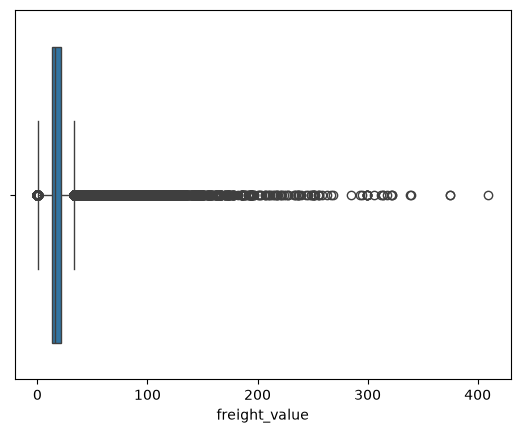

In [475]:
sns.boxplot(x=orders_items_clean["freight_value"])

In [476]:
#finding the outliers in freight value
Q1=orders_items_clean["freight_value"].quantile(0.25)
Q3=orders_items_clean["freight_value"].quantile(0.75)
IQR=Q3-Q1
lower_bound=Q1-1.5*IQR
upper_bound=Q3+1.5*IQR
print("lower bound:",lower_bound)
print("upper bound:",upper_bound)

lower bound: 0.9750000000000032
upper bound: 33.254999999999995


In [477]:
freight_outliers=orders_items_clean[(orders_items_clean["freight_value"]<lower_bound)|(orders_items_clean["freight_value"]>upper_bound)]
print("number_of_fright_outliers:",len(freight_outliers))

number_of_fright_outliers: 12134


In [478]:
freight_outliers.sort_values(
    by="freight_value",
    ascending=False
).head(10)

,order_id,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value
73486,a77e1550db865202c56b19ddc6dc4d53,1,ec31d2a17b299511e7c8627be9337b9b,257e61d3251fb5efb9daadddbc2cf7ca,2018-04-25 06:55:13,979.00,409.68
28044,3fde74c28a3d5d618c00f26d51baafa0,1,a3cd9517ebf5a50dca25acce54f3b171,6fa9202c10491e472dffd59a3e82b2a3,2018-08-22 03:15:09,2338.08,375.28
3303,076d1555fb53a89b0ef4d529e527a0f6,1,a3cd9517ebf5a50dca25acce54f3b171,6fa9202c10491e472dffd59a3e82b2a3,2018-08-07 04:35:22,2338.08,375.28
69797,9f49bd16053df810384e793386312674,1,256a9c364b75753b97bee410c9491ad8,5c030029b5916fed0986310385ec9009,2018-08-02 03:44:28,1149.00,339.59
16731,264a7e199467906c0727394df82d1a6a,1,97c948ebc8c04b26b7bbb095d4228f2a,17f51e7198701186712e53a39c564617,2018-04-23 17:15:10,1050.00,338.30
87936,c7a07ddd52bbe18b61da49a8d89853d3,1,97c948ebc8c04b26b7bbb095d4228f2a,17f51e7198701186712e53a39c564617,2018-07-31 10:45:11,1050.00,322.10
5037,0b6230647ed16f4b3e70282dc4b5b87f,1,46e24ce614899e36617e37ea1e4aa6ff,17f51e7198701186712e53a39c564617,2018-06-01 19:14:24,1050.00,321.88
3584,0822bcde10bb5d023755a71bc8f7797f,1,363a9f5b97bf194da23858be722a7aa5,9596c870880d900012f2e8e6e30d06d7,2018-05-10 23:52:39,990.00,321.46
29787,43bdbd9dc0931d72befdf4765af6c442,1,7e53e051875b2a0c9f22acd8a9a29a20,eeb6de78f79159600292e314a77cbd18,2018-07-12 08:35:21,3089.00,317.47
48320,6ddfbf514959b49b6410c01ad93054bb,1,363a9f5b97bf194da23858be722a7aa5,9596c870880d900012f2e8e6e30d06d7,2017-11-30 15:10:57,1045.00,314.40


### Freight Value Outlier Analysis

The IQR method identified 12,134 outliers in the `freight_value` column. The highest freight charges were inspected and found to be associated with products that also had relatively high prices.

These values may represent legitimate shipping costs related to product characteristics or delivery distance. Since no confirmed data-entry errors were identified, the outliers were retained without modification.

<Axes: xlabel='price'>

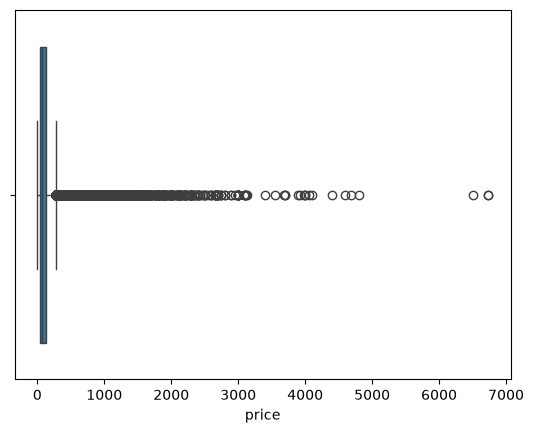

In [479]:
sns.boxplot(x=orders_items_clean["price"])

In [480]:
#finding the outliers in price
Q1=orders_items_clean["price"].quantile(0.25)
Q3=orders_items_clean["price"].quantile(0.75)
IQR=Q3-Q1
lower_bound=Q1-1.5*IQR
upper_bound=Q3+1.5*IQR
print("lower bound:",lower_bound)
print("upper bound:",upper_bound)

lower bound: -102.6
upper bound: 277.4


In [481]:
price_outliers=orders_items_clean[(orders_items_clean["price"]<lower_bound)|(orders_items_clean["price"]>upper_bound)]
print("no_of_price_outliers:",len(price_outliers))

no_of_price_outliers: 8427


In [482]:
price_outliers.sort_values(
    by="price",
    ascending=False
).head(10)

,order_id,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value
3556,0812eb902a67711a1cb742b3cdaa65ae,1,489ae2aa008f021502940f251d4cce7f,e3b4998c7a498169dc7bce44e6bb6277,2017-02-16 20:37:36,6735.00,194.31
112233,fefacc66af859508bf1a7934eab1e97f,1,69c590f7ffc7bf8db97190b6cb6ed62e,80ceebb4ee9b31afb6c6a916a574a1e2,2018-08-02 04:05:13,6729.00,193.21
107841,f5136e38d1a14a4dbd87dff67da82701,1,1bdf5e6731585cf01aa8169c7028d6ad,ee27a8f15b1dded4d213a468ba4eb391,2017-06-15 02:45:17,6499.00,227.66
74336,a96610ab360d42a2e5335a3998b4718a,1,a6492cc69376c469ab6f61d8f44de961,59417c56835dd8e2e72f91f809cd4092,2017-04-18 13:25:18,4799.00,151.34
11249,199af31afc78c699f0dbf71fb178d4d4,1,c3ed642d592594bb648ff4a04cee2747,59417c56835dd8e2e72f91f809cd4092,2017-05-09 15:50:15,4690.00,74.34
62086,8dbc85d1447242f3b127dda390d56e19,1,259037a6a41845e455183f89c5035f18,c72de06d72748d1a0dfb2125be43ba63,2018-06-28 12:36:36,4590.00,91.78
29193,426a9742b533fc6fed17d1fd6d143d7e,1,a1beef8f3992dbd4cd8726796aa69c53,512d298ac2a96d1931b6bd30aa21f61d,2018-08-16 14:24:28,4399.87,113.45
45843,68101694e5c5dc7330c91e1bbc36214f,1,6cdf8fc1d741c76586d8b6b15e9eef30,ed4acab38528488b65a9a9c603ff024a,2018-04-05 08:27:27,4099.99,75.27
78310,b239ca7cd485940b31882363b52e6674,1,dd113cb02b2af9c8e5787e8f1f0722f6,821fb029fc6e495ca4f08a35d51e53a5,2018-08-02 08:15:14,4059.00,104.51
59137,86c4eab1571921a6a6e248ed312f5a5a,1,6902c1962dd19d540807d0ab8fade5c6,fa1c13f2614d7b5c4749cbc52fecda94,2017-03-23 20:08:04,3999.90,17.01


### Price Outlier Analysis

The IQR method identified 8,427 outliers in the `price` column. The 10 highest prices were inspected, ranging from R$3,999.90 to R$6,735.00.

These values may represent high-value products and are not confirmed data-entry errors. Therefore, all price outliers were retained without modification.

In [483]:
orders_items_clean["order_item_id"].value_counts().sort_index()

order_item_id
1     98666
2      9803
3      2287
4       965
5       460
6       256
7        58
8        36
9        28
10       25
11       17
12       13
13        8
14        7
15        5
16        3
17        3
18        3
19        3
20        3
21        1
Name: count, dtype: int64

In [484]:
customers_clean.head()

,customer_id,customer_unique_id,customer_zip_code_prefix,customer_city,customer_state
0,06b8999e2fba1a1fbc88172c00ba8bc7,861eff4711a542e4b93843c6dd7febb0,14409,franca,SP
1,18955e83d337fd6b2def6b18a428ac77,290c77bc529b7ac935b93aa66c333dc3,9790,sao bernardo do campo,SP
2,4e7b3e00288586ebd08712fdd0374a03,060e732b5b29e8181a18229c7b0b2b5e,1151,sao paulo,SP
3,b2b6027bc5c5109e529d4dc6358b12c3,259dac757896d24d7702b9acbbff3f3c,8775,mogi das cruzes,SP
4,4f2d8ab171c80ec8364f7c12e35b23ad,345ecd01c38d18a9036ed96c73b8d066,13056,campinas,SP


In [485]:
customers_clean.info()

<class 'pandas.DataFrame'>
RangeIndex: 99441 entries, 0 to 99440
Data columns (total 5 columns):
 #   Column                    Non-Null Count  Dtype
---  ------                    --------------  -----
 0   customer_id               99441 non-null  str  
 1   customer_unique_id        99441 non-null  str  
 2   customer_zip_code_prefix  99441 non-null  int64
 3   customer_city             99441 non-null  str  
 4   customer_state            99441 non-null  str  
dtypes: int64(1), str(4)
memory usage: 3.8 MB


In [486]:
customers_clean.isnull().sum()

customer_id                 0
customer_unique_id          0
customer_zip_code_prefix    0
customer_city               0
customer_state              0
dtype: int64

In [487]:
customers_clean["customer_unique_id"].duplicated().sum()

np.int64(3345)

In [488]:
customers_clean["customer_unique_id"].value_counts().head(10)

customer_unique_id
8d50f5eadf50201ccdcedfb9e2ac8455    17
3e43e6105506432c953e165fb2acf44c     9
1b6c7548a2a1f9037c1fd3ddfed95f33     7
6469f99c1f9dfae7733b25662e7f1782     7
ca77025e7201e3b30c44b472ff346268     7
47c1a3033b8b77b3ab6e109eb4d5fdf3     6
dc813062e0fc23409cd255f7f53c7074     6
63cfc61cee11cbe306bff5857d00bfe4     6
f0e310a6839dce9de1638e0fe5ab282a     6
de34b16117594161a6a89c50b289d35a     6
Name: count, dtype: int64

In [489]:
customers_clean["customer_city"].value_counts().head(10)

customer_city
sao paulo                15540
rio de janeiro            6882
belo horizonte            2773
brasilia                  2131
curitiba                  1521
campinas                  1444
porto alegre              1379
salvador                  1245
guarulhos                 1189
sao bernardo do campo      938
Name: count, dtype: int64

In [490]:
customers_clean["customer_state"].value_counts()

customer_state
SP    41746
RJ    12852
MG    11635
RS     5466
PR     5045
SC     3637
BA     3380
DF     2140
ES     2033
GO     2020
PE     1652
CE     1336
PA      975
MT      907
MA      747
MS      715
PB      536
PI      495
RN      485
AL      413
SE      350
TO      280
RO      253
AM      148
AC       81
AP       68
RR       46
Name: count, dtype: int64

In [491]:
customers_clean.duplicated().sum()

np.int64(0)

In [492]:
products_clean.info()

<class 'pandas.DataFrame'>
RangeIndex: 32951 entries, 0 to 32950
Data columns (total 9 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   product_id                  32951 non-null  str    
 1   product_category_name       32341 non-null  str    
 2   product_name_lenght         32341 non-null  float64
 3   product_description_lenght  32341 non-null  float64
 4   product_photos_qty          32341 non-null  float64
 5   product_weight_g            32949 non-null  float64
 6   product_length_cm           32949 non-null  float64
 7   product_height_cm           32949 non-null  float64
 8   product_width_cm            32949 non-null  float64
dtypes: float64(7), str(2)
memory usage: 2.3 MB


In [493]:
products_clean.head()

,product_id,product_category_name,product_name_lenght,product_description_lenght,product_photos_qty,product_weight_g,product_length_cm,product_height_cm,product_width_cm
0,1e9e8ef04dbcff4541ed26657ea517e5,perfumaria,40.0,287.0,1.0,225.0,16.0,10.0,14.0
1,3aa071139cb16b67ca9e5dea641aaa2f,artes,44.0,276.0,1.0,1000.0,30.0,18.0,20.0
2,96bd76ec8810374ed1b65e291975717f,esporte_lazer,46.0,250.0,1.0,154.0,18.0,9.0,15.0
3,cef67bcfe19066a932b7673e239eb23d,bebes,27.0,261.0,1.0,371.0,26.0,4.0,26.0
4,9dc1a7de274444849c219cff195d0b71,utilidades_domesticas,37.0,402.0,4.0,625.0,20.0,17.0,13.0


In [494]:
products_clean.isnull().sum()

product_id                      0
product_category_name         610
product_name_lenght           610
product_description_lenght    610
product_photos_qty            610
product_weight_g                2
product_length_cm               2
product_height_cm               2
product_width_cm                2
dtype: int64

In [495]:
products_clean[
    products_clean.isnull().any(axis=1)
].head(10)

,product_id,product_category_name,product_name_lenght,product_description_lenght,product_photos_qty,product_weight_g,product_length_cm,product_height_cm,product_width_cm
105,a41e356c76fab66334f36de622ecbd3a,NaN,NaN,NaN,NaN,650.0,17.0,14.0,12.0
128,d8dee61c2034d6d075997acef1870e9b,NaN,NaN,NaN,NaN,300.0,16.0,7.0,20.0
145,56139431d72cd51f19eb9f7dae4d1617,NaN,NaN,NaN,NaN,200.0,20.0,20.0,20.0
154,46b48281eb6d663ced748f324108c733,NaN,NaN,NaN,NaN,18500.0,41.0,30.0,41.0
197,5fb61f482620cb672f5e586bb132eae9,NaN,NaN,NaN,NaN,300.0,35.0,7.0,12.0
244,e10758160da97891c2fdcbc35f0f031d,NaN,NaN,NaN,NaN,2200.0,16.0,2.0,11.0
294,39e3b9b12cd0bf8ee681bbc1c130feb5,NaN,NaN,NaN,NaN,300.0,16.0,7.0,11.0
299,794de06c32a626a5692ff50e4985d36f,NaN,NaN,NaN,NaN,300.0,18.0,8.0,14.0
347,7af3e2da474486a3519b0cba9dea8ad9,NaN,NaN,NaN,NaN,200.0,22.0,14.0,14.0
428,629beb8e7317703dcc5f35b5463fd20e,NaN,NaN,NaN,NaN,1400.0,25.0,25.0,25.0


In [496]:
products_clean[
    products_clean["product_category_name"].isnull()
].isnull().sum()

product_id                      0
product_category_name         610
product_name_lenght           610
product_description_lenght    610
product_photos_qty            610
product_weight_g                1
product_length_cm               1
product_height_cm               1
product_width_cm                1
dtype: int64

In [497]:
products_clean[
    products_clean["product_weight_g"].isnull()
]

,product_id,product_category_name,product_name_lenght,product_description_lenght,product_photos_qty,product_weight_g,product_length_cm,product_height_cm,product_width_cm
8578,09ff539a621711667c43eba6a3bd8466,bebes,60.0,865.0,3.0,NaN,NaN,NaN,NaN
18851,5eb564652db742ff8f28759cd8d2652a,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


### Handling Missing Values

The products dataset contained missing values in the following columns:

- `product_category_name`: 610 missing values
- `product_name_length`: 610 missing values
- `product_description_length`: 610 missing values
- `product_photos_qty`: 610 missing values
- `product_weight_g`: 2 missing values
- `product_length_cm`: 2 missing values
- `product_height_cm`: 2 missing values
- `product_width_cm`: 2 missing values

The 610 missing values in the product category and descriptive columns were mostly associated with products whose information was unavailable. Two products also had missing weight and dimension information.

These missing values were retained because the actual information could not be reliably determined. No values were replaced with zero or arbitrary estimates, and no rows were removed solely because of missing values.

**Conclusion:** Missing values were investigated and documented. They were retained without imputation to avoid introducing inaccurate information into the dataset.

In [498]:
products_clean["product_id"].duplicated().sum()

np.int64(0)

In [499]:
products_clean.duplicated().sum()

np.int64(0)

In [500]:
products_clean["product_category_name"].value_counts().head(10)

product_category_name
cama_mesa_banho           3029
esporte_lazer             2867
moveis_decoracao          2657
beleza_saude              2444
utilidades_domesticas     2335
automotivo                1900
informatica_acessorios    1639
brinquedos                1411
relogios_presentes        1329
telefonia                 1134
Name: count, dtype: int64

In [501]:
products_clean["product_category_name"].str.strip().ne(
    products_clean["product_category_name"]
).sum()

np.int64(610)

In [502]:
products_clean["product_category_name"].notna().sum()

np.int64(32341)

In [503]:
s = products_clean["product_category_name"]

(s.notna() & s.str.strip().ne(s)).sum()

np.int64(0)

In [504]:
products_clean[
    (products_clean["product_weight_g"] <= 0) |
    (products_clean["product_length_cm"] <= 0) |
    (products_clean["product_height_cm"] <= 0) |
    (products_clean["product_width_cm"] <= 0)
]

,product_id,product_category_name,product_name_lenght,product_description_lenght,product_photos_qty,product_weight_g,product_length_cm,product_height_cm,product_width_cm
9769,81781c0fed9fe1ad6e8c81fca1e1cb08,cama_mesa_banho,51.0,529.0,1.0,0.0,30.0,25.0,30.0
13683,8038040ee2a71048d4bdbbdc985b69ab,cama_mesa_banho,48.0,528.0,1.0,0.0,30.0,25.0,30.0
14997,36ba42dd187055e1fbe943b2d11430ca,cama_mesa_banho,53.0,528.0,1.0,0.0,30.0,25.0,30.0
32079,e673e90efa65a5409ff4196c038bb5af,cama_mesa_banho,53.0,528.0,1.0,0.0,30.0,25.0,30.0


### Product Weight Validation

The validation check identified 4 products with a weight of 0 grams.
Since these products have non-zero dimensions, the zero weight values
may represent data-entry issues. The values were retained without
imputation because the actual product weights are unknown.

In [505]:
products_clean[
    products_clean["product_photos_qty"] <= 0
]

,product_id,product_category_name,product_name_lenght,product_description_lenght,product_photos_qty,product_weight_g,product_length_cm,product_height_cm,product_width_cm


In [506]:
products_clean[
    (products_clean["product_name_lenght"] <= 0) |
    (products_clean["product_description_lenght"] <= 0)
]

,product_id,product_category_name,product_name_lenght,product_description_lenght,product_photos_qty,product_weight_g,product_length_cm,product_height_cm,product_width_cm


In [507]:
products_clean.rename(columns={
    "product_name_lenght":"product_name_length",
    "product_description_lenght":"product_description_length"
},inplace=True)

C:\Users\Harsha K R\AppData\Local\Temp\ipykernel_9156\1788799525.py:1: Pandas4Warning: The inplace keyword in DataFrame.rename is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  products_clean.rename(columns={


In [508]:
products_clean["product_weight_g"].describe()

count    32949.000000
mean      2276.472488
std       4282.038731
min          0.000000
25%        300.000000
50%        700.000000
75%       1900.000000
max      40425.000000
Name: product_weight_g, dtype: float64

In [509]:
Q1 = products_clean["product_weight_g"].quantile(0.25)
Q3 = products_clean["product_weight_g"].quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

weight_outliers = products_clean[
    (products_clean["product_weight_g"] < lower_bound) |
    (products_clean["product_weight_g"] > upper_bound)
]

weight_outliers.shape

(4551, 9)

In [510]:
weight_outliers.sort_values(
    by="product_weight_g",
    ascending=False
).head(20)

,product_id,product_category_name,product_name_length,product_description_length,product_photos_qty,product_weight_g,product_length_cm,product_height_cm,product_width_cm
25166,26644690fde745fc4654719c3904e1db,cama_mesa_banho,59.0,534.0,1.0,40425.0,13.0,65.0,28.0
344,d0877f0094337c414d23f5a3c7bad20c,moveis_escritorio,48.0,489.0,2.0,30000.0,50.0,50.0,30.0
16365,f18e0f3757837733f36da5143ddccd73,beleza_saude,49.0,487.0,2.0,30000.0,69.0,66.0,50.0
16591,bd1fc5db666613cbd3cba3ef38d3c0f2,automotivo,36.0,2973.0,3.0,30000.0,66.0,66.0,43.0
26495,d15010eecc80e3a843ccb15865c328da,beleza_saude,57.0,430.0,1.0,30000.0,55.0,75.0,61.0
32532,90c1b4e040d1d1c45897ec2dad4a809d,moveis_sala,57.0,837.0,2.0,30000.0,63.0,63.0,74.0
16700,b575098a6da9b81384a7df56314b7f70,ferramentas_jardim,54.0,887.0,3.0,30000.0,47.0,62.0,62.0
16728,99ff40856c47a638df807c0a144470cc,moveis_sala,54.0,1108.0,2.0,30000.0,80.0,60.0,60.0
32491,2b752ed328ea866e4721ca4e236a416c,moveis_cozinha_area_de_servico_jantar_e_jardim,47.0,2201.0,4.0,30000.0,16.0,2.0,11.0
15982,c100e5fef1abb5e1c5054d1dac2d83ac,beleza_saude,57.0,534.0,1.0,30000.0,55.0,75.0,61.0



### Product Weight Outlier Analysis

The IQR method identified 4,551 outliers in the `product_weight_g` column. The highest-weight products were inspected, and their categories and physical dimensions were found to be generally plausible.

Since the identified values may represent legitimate heavy products, the outliers were retained without modification. Four products with zero weight were separately identified as potentially invalid values and retained because their actual weights are unknown.


In [511]:
products_clean["product_length_cm"].describe()

count    32949.000000
mean        30.815078
std         16.914458
min          7.000000
25%         18.000000
50%         25.000000
75%         38.000000
max        105.000000
Name: product_length_cm, dtype: float64

In [512]:
Q1 = products_clean["product_length_cm"].quantile(0.25)
Q3 = products_clean["product_length_cm"].quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

length_outliers = products_clean[
    (products_clean["product_length_cm"] < lower_bound) |
    (products_clean["product_length_cm"] > upper_bound)
]

length_outliers.shape

(1380, 9)

In [513]:
length_outliers.sort_values(
    by="product_length_cm",
    ascending=False
)[[
    "product_id",
    "product_category_name",
    "product_length_cm",
    "product_height_cm",
    "product_width_cm",
    "product_weight_g"
]].head(10)

,product_id,product_category_name,product_length_cm,product_height_cm,product_width_cm,product_weight_g
32431,7138c5cd9a02964ede6383ffac29e5be,moveis_decoracao,105.0,3.0,70.0,2200.0
32348,99df954d850e77181a52864913d48147,moveis_decoracao,105.0,3.0,70.0,2250.0
88,7f34b85142d1ef9e077a0da9ada27385,moveis_decoracao,105.0,3.0,70.0,2300.0
32257,e02758c6570548237ebc9fe75b4701fb,esporte_lazer,105.0,8.0,25.0,5400.0
32211,a2359ef18f03db4e53c75d8c15172cfd,moveis_decoracao,105.0,3.0,70.0,2500.0
21026,ca8abbdcac2d082a56ff54df35aec76a,instrumentos_musicais,105.0,15.0,40.0,3000.0
9373,038e3a669bb495e56d9d609d874fb668,esporte_lazer,105.0,70.0,20.0,30000.0
8261,d159157f1837c548e960ea0e9b00b259,esporte_lazer,105.0,15.0,15.0,1300.0
8033,f6f66f6bb78ecbb86093da5be2f40304,moveis_decoracao,105.0,3.0,70.0,2650.0
9169,9c62adfd2a4126042e0410e01a0f1630,moveis_decoracao,105.0,3.0,70.0,2550.0


### Outlier Analysis – Product Length

The IQR method identified 1,380 outliers in the `product_length_cm` column.

The highest length values were inspected along with their product categories, heights, widths, and weights. The observed values appeared reasonable for the respective products. Some products with larger dimensions also had higher weights.

No clearly invalid product length values were identified during the inspection. Therefore, the outliers were considered potentially valid product measurements and were retained without modification.

**Conclusion:** The product length outliers were investigated and retained because the observed values appeared realistic and no sufficient evidence of data entry errors was found.

In [514]:
products_clean["product_height_cm"].describe()

count    32949.000000
mean        16.937661
std         13.637554
min          2.000000
25%          8.000000
50%         13.000000
75%         21.000000
max        105.000000
Name: product_height_cm, dtype: float64

In [515]:
Q1 = products_clean["product_height_cm"].quantile(0.25)
Q3 = products_clean["product_height_cm"].quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

height_outliers = products_clean[
    (products_clean["product_height_cm"] < lower_bound) |
    (products_clean["product_height_cm"] > upper_bound)
]

height_outliers.shape

(1892, 9)

In [516]:
height_outliers.sort_values(
    by="product_height_cm",
    ascending=False
)[[
    "product_id",
    "product_category_name",
    "product_length_cm",
    "product_height_cm",
    "product_width_cm",
    "product_weight_g"
]].head(10)

,product_id,product_category_name,product_length_cm,product_height_cm,product_width_cm,product_weight_g
1498,e4e9fa024c5f014419b395452a41987c,esporte_lazer,16.0,105.0,55.0,3450.0
6007,d5365b4fc46af0e0679ce35e818b4b0a,esporte_lazer,16.0,105.0,55.0,15450.0
28375,1ca99da10c4b800de39096631ed2e773,esporte_lazer,17.0,105.0,12.0,800.0
29886,d04bbac48960ecb7ea311b00ca6e1cb7,industria_comercio_e_negocios,18.0,105.0,30.0,11325.0
6105,83f6e0a993efdfa2bf9550a204422cb7,moveis_cozinha_area_de_servico_jantar_e_jardim,60.0,105.0,15.0,15800.0
29141,00e32638060f6356e6f00749dc466b5c,esporte_lazer,20.0,105.0,20.0,7050.0
29038,88e84a987b4681434dedc0bc9e00826b,industria_comercio_e_negocios,16.0,105.0,30.0,7800.0
29413,a7f4ab2b8fc3ee762e05b6eda08acb93,esporte_lazer,16.0,105.0,15.0,750.0
6149,58306668d7263e8ebd2d5c69ef31cc23,beleza_saude,25.0,105.0,12.0,5300.0
10457,ef4f89f8ee26b84496a7f8e7dc76029d,casa_construcao,50.0,105.0,15.0,9150.0


### Outlier Analysis – Product Height

The IQR method identified 1,892 outliers in the `product_height_cm` column.

The top 10 highest product height values were inspected along with their product categories, lengths, widths, and weights. The observed measurements appeared plausible for the respective products. Although some products had a height of 105 cm, their other dimensions and weights varied based on the product category.

No clear evidence of incorrect data entry was identified during the inspection. Therefore, the detected outliers were retained without modification.

**Conclusion:** Product height outliers were investigated and retained because the observed values appeared realistic. No changes were made to the original measurements.

In [517]:
products_clean["product_width_cm"].describe()

count    32949.000000
mean        23.196728
std         12.079047
min          6.000000
25%         15.000000
50%         20.000000
75%         30.000000
max        118.000000
Name: product_width_cm, dtype: float64

In [518]:
Q1 = products_clean["product_width_cm"].quantile(0.25)
Q3 = products_clean["product_width_cm"].quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

width_outliers = products_clean[
    (products_clean["product_width_cm"] < lower_bound) |
    (products_clean["product_width_cm"] > upper_bound)
]

width_outliers.shape

(912, 9)

In [519]:
width_outliers.sort_values(
    by="product_width_cm",
    ascending=False
)[[
    "product_id",
    "product_category_name",
    "product_length_cm",
    "product_height_cm",
    "product_width_cm",
    "product_weight_g"
]].head(10)

,product_id,product_category_name,product_length_cm,product_height_cm,product_width_cm,product_weight_g
26970,b17808303e15dd50538c011b44295427,cama_mesa_banho,23.0,93.0,118.0,1050.0
475,a2f4e28e50f60566eeb99f842ffc0fd9,instrumentos_musicais,40.0,9.0,105.0,5850.0
23725,cb428376d66b5e216d2ef9f3b27fc172,instrumentos_musicais,45.0,14.0,105.0,5000.0
28739,3758055ab2434bd36ac78e00b15b5cf6,beleza_saude,50.0,8.0,105.0,600.0
25181,3b17f6528c9e2a01b2f75f844a60ddae,instrumentos_musicais,40.0,9.0,105.0,5000.0
19326,6d30e5e702df2b8719d9c6be1bdf425b,cool_stuff,27.0,23.0,105.0,25000.0
31050,83d68ad4e5707409089afff26a40b2df,brinquedos,50.0,14.0,104.0,13150.0
15308,e7248872169a7ab67e20c182aaf17976,instrumentos_musicais,35.0,9.0,103.0,5000.0
10256,68e6e8fd8c5f5b252b105d00daa9b57b,moveis_escritorio,39.0,13.0,102.0,13800.0
31163,e54c0428a8cf1b79f63823b92e20aacc,moveis_cozinha_area_de_servico_jantar_e_jardim,39.0,13.0,102.0,25800.0


### Outlier Analysis – Product Width

The IQR method identified 912 outliers in the `product_width_cm` column.

The 10 highest product width values were inspected along with their product categories, lengths, heights, and weights. The observed measurements appeared reasonable for the respective products. Some products had widths exceeding 100 cm, which may be valid depending on the product's physical dimensions.

No clear evidence of incorrect data entry was identified during the inspection. Therefore, the detected outliers were retained without modification.

**Conclusion:** Product width outliers were investigated and retained because the observed values appeared realistic. No changes were made to the original measurements.

In [520]:
# Dataset shape
print("Shape:", products_clean.shape)

# Missing values
print("\nMissing values:")
print(products_clean.isnull().sum())

# Duplicate product IDs
print("\nDuplicate product IDs:")
print(products_clean["product_id"].duplicated().sum())

# Data types
print("\nData types:")
print(products_clean.dtypes)

Shape: (32951, 9)

Missing values:
product_id                      0
product_category_name         610
product_name_length           610
product_description_length    610
product_photos_qty            610
product_weight_g                2
product_length_cm               2
product_height_cm               2
product_width_cm                2
dtype: int64

Duplicate product IDs:
0

Data types:
product_id                        str
product_category_name             str
product_name_length           float64
product_description_length    float64
product_photos_qty            float64
product_weight_g              float64
product_length_cm             float64
product_height_cm             float64
product_width_cm              float64
dtype: object


### Final Validation – Products Dataset

The products dataset was validated after the data cleaning and outlier analysis.

The dataset contains 32,951 rows and 9 columns. No duplicate product IDs were found. Missing values were investigated and retained without imputation. Outliers in product weight and dimensions were inspected and retained because the observed measurements appeared plausible.

The column names were corrected for consistency, and the data types were verified.

**Conclusion:** The products dataset passed the final validation checks and is ready for further analysis.

In [521]:
order_payments_clean.head()

,order_id,payment_sequential,payment_type,payment_installments,payment_value
0,b81ef226f3fe1789b1e8b2acac839d17,1,credit_card,8,99.33
1,a9810da82917af2d9aefd1278f1dcfa0,1,credit_card,1,24.39
2,25e8ea4e93396b6fa0d3dd708e76c1bd,1,credit_card,1,65.71
3,ba78997921bbcdc1373bb41e913ab953,1,credit_card,8,107.78
4,42fdf880ba16b47b59251dd489d4441a,1,credit_card,2,128.45


In [522]:
order_payments_clean.isnull().sum()

order_id                0
payment_sequential      0
payment_type            0
payment_installments    0
payment_value           0
dtype: int64

In [523]:
order_payments_clean.duplicated().sum()

np.int64(0)

In [524]:
order_payments_clean.info()

<class 'pandas.DataFrame'>
RangeIndex: 103886 entries, 0 to 103885
Data columns (total 5 columns):
 #   Column                Non-Null Count   Dtype  
---  ------                --------------   -----  
 0   order_id              103886 non-null  str    
 1   payment_sequential    103886 non-null  int64  
 2   payment_type          103886 non-null  str    
 3   payment_installments  103886 non-null  int64  
 4   payment_value         103886 non-null  float64
dtypes: float64(1), int64(2), str(2)
memory usage: 4.0 MB


In [525]:
order_payments_clean[order_payments_clean["payment_type"]=="not_defined"]

,order_id,payment_sequential,payment_type,payment_installments,payment_value
51280,4637ca194b6387e2d538dc89b124b0ee,1,not_defined,1,0.0
57411,00b1cb0320190ca0daa2c88b35206009,1,not_defined,1,0.0
94427,c8c528189310eaa44a745b8d9d26908b,1,not_defined,1,0.0


In [526]:
(order_payments_clean["payment_type"].str.strip().ne(order_payments_clean["payment_type"])).sum()

np.int64(0)

In [527]:
order_payments_clean[
    order_payments_clean["payment_type"] == "not_defined"
].merge(
    orders_clean[["order_id", "order_status"]],
    on="order_id",
    how="left"
)

,order_id,payment_sequential,payment_type,payment_installments,payment_value,order_status
0,4637ca194b6387e2d538dc89b124b0ee,1,not_defined,1,0.0,canceled
1,00b1cb0320190ca0daa2c88b35206009,1,not_defined,1,0.0,canceled
2,c8c528189310eaa44a745b8d9d26908b,1,not_defined,1,0.0,canceled


### Investigation of Unusual Payment Records

Three records were identified with the following values:

- `payment_type`: `not_defined`
- `payment_value`: `0.0`
- `payment_installments`: 1

After investigating the corresponding order records, all three orders were found to have a `canceled` status.

These records may represent orders that were canceled before a payment was completed. The values were not treated as missing values or incorrect data.

**Conclusion:** The three records were retained without modification because they were associated with canceled orders. Their payment type and payment value were considered explainable within the context of the order status.

In [528]:
(order_payments_clean["payment_value"]<0).sum()

np.int64(0)

In [529]:
Q1 = order_payments_clean["payment_value"].quantile(0.25)
Q3 = order_payments_clean["payment_value"].quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

payment_outliers = order_payments_clean[
    (order_payments_clean["payment_value"] < lower_bound) |
    (order_payments_clean["payment_value"] > upper_bound)
]

payment_outliers.shape

(7981, 5)

In [530]:
payment_outliers.sort_values(
    by="payment_value",
    ascending=False
).head(10)

,order_id,payment_sequential,payment_type,payment_installments,payment_value
52107,03caa2c082116e1d31e67e9ae3700499,1,credit_card,1,13664.08
34370,736e1922ae60d0d6a89247b851902527,1,boleto,1,7274.88
41419,0812eb902a67711a1cb742b3cdaa65ae,1,credit_card,8,6929.31
49581,fefacc66af859508bf1a7934eab1e97f,1,boleto,1,6922.21
85539,f5136e38d1a14a4dbd87dff67da82701,1,boleto,1,6726.66
62409,2cc9089445046817a7539d90805e6e5a,1,boleto,1,6081.54
43232,a96610ab360d42a2e5335a3998b4718a,1,credit_card,10,4950.34
70320,b4c4b76c642808cbe472a32b86cddc95,1,credit_card,5,4809.44
6440,199af31afc78c699f0dbf71fb178d4d4,1,credit_card,8,4764.34
67546,8dbc85d1447242f3b127dda390d56e19,1,credit_card,8,4681.78


In [531]:
orders_items_totals=orders_items_clean.groupby("order_id").agg(
    orders_items_total=("price","sum"),
    freight_total=("freight_value","sum")
)
orders_items_totals["order_total"] = (
    orders_items_totals["orders_items_total"] +
    orders_items_totals["freight_total"]
)
payment_totals=order_payments_clean.groupby("order_id").agg(
    payment_total=("payment_value","sum")
)
payment_comparison=orders_items_totals.join(payment_totals)
payment_comparison["difference"]=payment_comparison["order_total"]-payment_comparison["payment_total"]

In [532]:
orders_items_totals

,orders_items_total,freight_total,order_total
order_id,,,
00010242fe8c5a6d1ba2dd792cb16214,58.90,13.29,72.19
00018f77f2f0320c557190d7a144bdd3,239.90,19.93,259.83
000229ec398224ef6ca0657da4fc703e,199.00,17.87,216.87
00024acbcdf0a6daa1e931b038114c75,12.99,12.79,25.78
00042b26cf59d7ce69dfabb4e55b4fd9,199.90,18.14,218.04
...,...,...,...
fffc94f6ce00a00581880bf54a75a037,299.99,43.41,343.40
fffcd46ef2263f404302a634eb57f7eb,350.00,36.53,386.53
fffce4705a9662cd70adb13d4a31832d,99.90,16.95,116.85


In [533]:
payment_comparison.sort_values(by="payment_total",ascending=False).head(20)

,orders_items_total,freight_total,order_total,payment_total,difference
order_id,,,,,
03caa2c082116e1d31e67e9ae3700499,13440.00,224.08,13664.08,13664.08,0.000000e+00
736e1922ae60d0d6a89247b851902527,7160.00,114.88,7274.88,7274.88,0.000000e+00
0812eb902a67711a1cb742b3cdaa65ae,6735.00,194.31,6929.31,6929.31,0.000000e+00
fefacc66af859508bf1a7934eab1e97f,6729.00,193.21,6922.21,6922.21,0.000000e+00
f5136e38d1a14a4dbd87dff67da82701,6499.00,227.66,6726.66,6726.66,0.000000e+00
2cc9089445046817a7539d90805e6e5a,5934.60,146.94,6081.54,6081.54,0.000000e+00
a96610ab360d42a2e5335a3998b4718a,4799.00,151.34,4950.34,4950.34,0.000000e+00
b4c4b76c642808cbe472a32b86cddc95,4599.90,209.54,4809.44,4809.44,0.000000e+00
199af31afc78c699f0dbf71fb178d4d4,4690.00,74.34,4764.34,4764.34,0.000000e+00


### Outlier Analysis – Payment Value

The IQR method identified 7,981 outliers in the `payment_value` column.

The highest payment values were inspected and compared with their corresponding order totals. The order totals were calculated using the sum of product prices and freight values.

The comparison showed that the payment totals matched the corresponding order totals for the inspected orders. No discrepancies were identified.

The high payment values were considered legitimate transactions rather than data entry errors.

**Conclusion:** Payment value outliers were investigated and retained without modification because the inspected payment totals matched their corresponding order totals.

In [534]:
order_payments_clean["payment_installments"].value_counts().sort_index()

payment_installments
0         2
1     52546
2     12413
3     10461
4      7098
5      5239
6      3920
7      1626
8      4268
9       644
10     5328
11       23
12      133
13       16
14       15
15       74
16        5
17        8
18       27
20       17
21        3
22        1
23        1
24       18
Name: count, dtype: int64

In [535]:
order_payments_clean[
    order_payments_clean["payment_installments"] == 0
]

,order_id,payment_sequential,payment_type,payment_installments,payment_value
46982,744bade1fcf9ff3f31d860ace076d422,2,credit_card,0,58.69
79014,1a57108394169c0b47d8f876acc9ba2d,2,credit_card,0,129.94


In [536]:
order_payments_clean[
    order_payments_clean["order_id"].isin([
        "744bade1fcf9ff3f31d860ace076d422",
        "1a57108394169c0b47d8f876acc9ba2d"
    ])
].sort_values("order_id")

,order_id,payment_sequential,payment_type,payment_installments,payment_value
79014,1a57108394169c0b47d8f876acc9ba2d,2,credit_card,0,129.94
46982,744bade1fcf9ff3f31d860ace076d422,2,credit_card,0,58.69


In [537]:
order_payments_clean["payment_sequential"].value_counts().sort_index()

payment_sequential
1     99360
2      3039
3       581
4       278
5       170
6       118
7        82
8        54
9        43
10       34
11       29
12       21
13       13
14       10
15        8
16        6
17        6
18        6
19        6
20        4
21        4
22        3
23        2
24        2
25        2
26        2
27        1
28        1
29        1
Name: count, dtype: int64

In [538]:
print("Shape:", order_payments_clean.shape)

print("\nMissing values:")
print(order_payments_clean.isnull().sum())

print("\nDuplicate rows:", order_payments_clean.duplicated().sum())

print("\nData types:")
print(order_payments_clean.dtypes)

Shape: (103886, 5)

Missing values:
order_id                0
payment_sequential      0
payment_type            0
payment_installments    0
payment_value           0
dtype: int64

Duplicate rows: 0

Data types:
order_id                    str
payment_sequential        int64
payment_type                str
payment_installments      int64
payment_value           float64
dtype: object


In [539]:
order_reviews_clean.head()

,review_id,order_id,review_score,review_comment_title,review_comment_message,review_creation_date,review_answer_timestamp
0,7bc2406110b926393aa56f80a40eba40,73fc7af87114b39712e6da79b0a377eb,4,NaN,NaN,2018-01-18 00:00:00,2018-01-18 21:46:59
1,80e641a11e56f04c1ad469d5645fdfde,a548910a1c6147796b98fdf73dbeba33,5,NaN,NaN,2018-03-10 00:00:00,2018-03-11 03:05:13
2,228ce5500dc1d8e020d8d1322874b6f0,f9e4b658b201a9f2ecdecbb34bed034b,5,NaN,NaN,2018-02-17 00:00:00,2018-02-18 14:36:24
3,e64fb393e7b32834bb789ff8bb30750e,658677c97b385a9be170737859d3511b,5,NaN,Recebi bem antes do prazo estipulado.,2017-04-21 00:00:00,2017-04-21 22:02:06
4,f7c4243c7fe1938f181bec41a392bdeb,8e6bfb81e283fa7e4f11123a3fb894f1,5,NaN,Parabéns lojas lannister adorei comprar pela I...,2018-03-01 00:00:00,2018-03-02 10:26:53


In [540]:
order_reviews_clean.dtypes

review_id                    str
order_id                     str
review_score               int64
review_comment_title         str
review_comment_message       str
review_creation_date         str
review_answer_timestamp      str
dtype: object

In [541]:
order_reviews_clean["review_creation_date"]=pd.to_datetime(order_reviews_clean["review_creation_date"],errors="coerce")
order_reviews_clean["review_answer_timestamp"]=pd.to_datetime(order_reviews_clean["review_answer_timestamp"],errors="coerce")

In [542]:
order_reviews_clean["review_score"].unique()

array([4, 5, 1, 3, 2])

In [543]:
order_reviews_clean.isnull().sum()

review_id                      0
order_id                       0
review_score                   0
review_comment_title       87656
review_comment_message     58247
review_creation_date           0
review_answer_timestamp        0
dtype: int64

In [544]:
order_reviews_clean[order_reviews_clean["review_id"].duplicated(keep=False)].sort_values("review_id").head(10)

,review_id,order_id,review_score,review_comment_title,review_comment_message,review_creation_date,review_answer_timestamp
46678,00130cbe1f9d422698c812ed8ded1919,dfcdfc43867d1c1381bfaf62d6b9c195,1,NaN,"O cartucho ""original HP"" 60XL não é reconhecid...",2018-03-07,2018-03-20 18:08:23
29841,00130cbe1f9d422698c812ed8ded1919,04a28263e085d399c97ae49e0b477efa,1,NaN,"O cartucho ""original HP"" 60XL não é reconhecid...",2018-03-07,2018-03-20 18:08:23
90677,0115633a9c298b6a98bcbe4eee75345f,78a4201f58af3463bdab842eea4bc801,5,NaN,NaN,2017-09-21,2017-09-26 03:27:47
63193,0115633a9c298b6a98bcbe4eee75345f,0c9850b2c179c1ef60d2855e2751d1fa,5,NaN,NaN,2017-09-21,2017-09-26 03:27:47
92876,0174caf0ee5964646040cd94e15ac95e,f93a732712407c02dce5dd5088d0f47b,1,NaN,Produto entregue dentro de embalagem do fornec...,2018-03-07,2018-03-08 03:00:53
57280,0174caf0ee5964646040cd94e15ac95e,74db91e33b4e1fd865356c89a61abf1f,1,NaN,Produto entregue dentro de embalagem do fornec...,2018-03-07,2018-03-08 03:00:53
54832,017808d29fd1f942d97e50184dfb4c13,8daaa9e99d60fbba579cc1c3e3bfae01,5,NaN,NaN,2018-03-02,2018-03-05 01:43:30
99167,017808d29fd1f942d97e50184dfb4c13,b1461c8882153b5fe68307c46a506e39,5,NaN,NaN,2018-03-02,2018-03-05 01:43:30
20621,0254bd905dc677a6078990aad3331a36,5bf226cf882c5bf4247f89a97c86f273,1,NaN,O pedido consta de 2 produtos e até agora rece...,2017-09-09,2017-09-13 09:52:44
96080,0254bd905dc677a6078990aad3331a36,331b367bdd766f3d1cf518777317b5d9,1,NaN,O pedido consta de 2 produtos e até agora rece...,2017-09-09,2017-09-13 09:52:44


In [545]:
duplicate_reviews = order_reviews_clean[
    order_reviews_clean["review_id"].duplicated(keep=False)
]

duplicate_reviews.groupby("review_id").agg(
    order_count=("order_id", "nunique"),
    score_count=("review_score", "nunique"),
    message_count=("review_comment_message", "nunique"),
    creation_date_count=("review_creation_date", "nunique"),
    answer_timestamp_count=("review_answer_timestamp", "nunique")
).sort_values("order_count", ascending=False).head(10)

,order_count,score_count,message_count,creation_date_count,answer_timestamp_count
review_id,,,,,
4219a80ab469e3fc9901437b73da3f75,3,1,1,1,1
7b606b0d57b078384f0b58eac1d41d78,3,1,0,1,1
0c76e7a547a531e7bf9f0b99cba071c1,3,1,0,1,1
69a1068c3128a14994e3e422e4539e04,3,1,0,1,1
308316408775d1600dad81bd3184556d,3,1,1,1,1
44e9f871226d8a130de3fc39dfbdf0c5,3,1,0,1,1
2172867fd5b1a55f98fe4608e1547b4b,3,1,1,1,1
9e25d6e3025e9b9a0fc7f03588d33e2b,3,1,1,1,1
38821b5c496b678cf91acc34892805ad,3,1,0,1,1


In [546]:
order_reviews_clean.duplicated(
    subset=["review_id", "order_id"]
).sum()

np.int64(0)

In [547]:
print("Minimum score:", order_reviews_clean["review_score"].min())
print("Maximum score:", order_reviews_clean["review_score"].max())

Minimum score: 1
Maximum score: 5


In [548]:
print("Shape:", order_reviews_clean.shape)

print("\nMissing values:")
print(order_reviews_clean.isnull().sum())

print("\nDuplicate rows:", order_reviews_clean.duplicated().sum())

print("\nData types:")
print(order_reviews_clean.dtypes)

Shape: (99224, 7)

Missing values:
review_id                      0
order_id                       0
review_score                   0
review_comment_title       87656
review_comment_message     58247
review_creation_date           0
review_answer_timestamp        0
dtype: int64

Duplicate rows: 0

Data types:
review_id                             str
order_id                              str
review_score                        int64
review_comment_title                  str
review_comment_message                str
review_creation_date       datetime64[us]
review_answer_timestamp    datetime64[us]
dtype: object


In [549]:
print("Category Translation:", product_category_name_translation_clean.shape)
print("Geolocation:", geolocation_clean.shape)
print("Sellers:", sellers_clean.shape)

Category Translation: (71, 2)
Geolocation: (1000163, 5)
Sellers: (3095, 4)


In [550]:
print(product_category_name_translation_clean.isnull().sum())
print(geolocation_clean.isnull().sum())
print(sellers_clean.isnull().sum())

product_category_name            0
product_category_name_english    0
dtype: int64
geolocation_zip_code_prefix    0
geolocation_lat                0
geolocation_lng                0
geolocation_city               0
geolocation_state              0
dtype: int64
seller_id                 0
seller_zip_code_prefix    0
seller_city               0
seller_state              0
dtype: int64


In [551]:
product_category_name_translation_clean.head()

,product_category_name,product_category_name_english
0,beleza_saude,health_beauty
1,informatica_acessorios,computers_accessories
2,automotivo,auto
3,cama_mesa_banho,bed_bath_table
4,moveis_decoracao,furniture_decor


In [552]:
product_category_name_translation_clean.duplicated().sum()

np.int64(0)

In [553]:
product_category_name_translation_clean[
    "product_category_name"
].duplicated().sum()

np.int64(0)

In [554]:
product_category_name_translation_clean[
    "product_category_name_english"
].duplicated().sum()

np.int64(0)

In [555]:
sellers_clean.head()

,seller_id,seller_zip_code_prefix,seller_city,seller_state
0,3442f8959a84dea7ee197c632cb2df15,13023,campinas,SP
1,d1b65fc7debc3361ea86b5f14c68d2e2,13844,mogi guacu,SP
2,ce3ad9de960102d0677a81f5d0bb7b2d,20031,rio de janeiro,RJ
3,c0f3eea2e14555b6faeea3dd58c1b1c3,4195,sao paulo,SP
4,51a04a8a6bdcb23deccc82b0b80742cf,12914,braganca paulista,SP


In [557]:
sellers_clean.duplicated().sum()

np.int64(0)

In [ ]:
sellers_clean["seller_id"].duplicated().sum()

np.int64(0)

In [ ]:
sellers_clean["seller_state"].value_counts()

seller_state
SP    1849
PR     349
MG     244
SC     190
RJ     171
RS     129
GO      40
DF      30
ES      23
BA      19
CE      13
PE       9
PB       6
RN       5
MS       5
MT       4
RO       2
SE       2
AC       1
PI       1
MA       1
AM       1
PA       1
Name: count, dtype: int64

In [558]:
sellers_clean["seller_city"].value_counts()

seller_city
sao paulo                 694
curitiba                  127
rio de janeiro             96
belo horizonte             68
ribeirao preto             52
                         ... 
aparecida de goiania        1
bandeirantes                1
vitoria de santo antao      1
palotina                    1
leme                        1
Name: count, Length: 611, dtype: int64

In [559]:
sellers_clean["seller_city"].str.strip().ne(
    sellers_clean["seller_city"]
).sum()

np.int64(0)

In [560]:
sellers_clean["seller_city"].value_counts().head(15)

seller_city
sao paulo                694
curitiba                 127
rio de janeiro            96
belo horizonte            68
ribeirao preto            52
guarulhos                 50
ibitinga                  49
santo andre               45
campinas                  41
maringa                   40
sao jose do rio preto     33
sao bernardo do campo     32
osasco                    32
sorocaba                  32
brasilia                  28
Name: count, dtype: int64

In [561]:
sellers_clean["seller_zip_code_prefix"].describe()

count     3095.000000
mean     32291.059451
std      32713.453830
min       1001.000000
25%       7093.500000
50%      14940.000000
75%      64552.500000
max      99730.000000
Name: seller_zip_code_prefix, dtype: float64

In [563]:
sellers_clean["seller_zip_code_prefix"].dtype

dtype('int64')

In [564]:
sellers_clean["seller_zip_code_prefix"].nunique()

2246

In [565]:
sellers_clean["seller_zip_code_prefix"].astype(str).str.len().value_counts()

seller_zip_code_prefix
5    2068
4    1027
Name: count, dtype: int64

In [566]:
sellers_clean["seller_zip_code_prefix"] = (
    sellers_clean["seller_zip_code_prefix"]
    .astype(str)
    .str.zfill(5)
)

In [568]:
sellers_clean["seller_zip_code_prefix"].astype(str).str.len().value_counts()

seller_zip_code_prefix
5    3095
Name: count, dtype: int64

In [570]:
print(
    sellers_clean["seller_city"].str.strip().ne(
        sellers_clean["seller_city"]
    ).sum()
)

print(
    sellers_clean["seller_state"].str.strip().ne(
        sellers_clean["seller_state"]
    ).sum()
)

0
0


In [571]:
print("Shape:", sellers_clean.shape)

print("\nData types:")
print(sellers_clean.dtypes)

print("\nMissing values:")
print(sellers_clean.isnull().sum())

print("\nDuplicate rows:")
print(sellers_clean.duplicated().sum())

Shape: (3095, 4)

Data types:
seller_id                 str
seller_zip_code_prefix    str
seller_city               str
seller_state              str
dtype: object

Missing values:
seller_id                 0
seller_zip_code_prefix    0
seller_city               0
seller_state              0
dtype: int64

Duplicate rows:
0


In [572]:
geolocation_clean.head()

,geolocation_zip_code_prefix,geolocation_lat,geolocation_lng,geolocation_city,geolocation_state
0,1037,-23.545621,-46.639292,sao paulo,SP
1,1046,-23.546081,-46.644820,sao paulo,SP
2,1046,-23.546129,-46.642951,sao paulo,SP
3,1041,-23.544392,-46.639499,sao paulo,SP
4,1035,-23.541578,-46.641607,sao paulo,SP


In [573]:
geolocation_clean.info()

<class 'pandas.DataFrame'>
RangeIndex: 1000163 entries, 0 to 1000162
Data columns (total 5 columns):
 #   Column                       Non-Null Count    Dtype  
---  ------                       --------------    -----  
 0   geolocation_zip_code_prefix  1000163 non-null  int64  
 1   geolocation_lat              1000163 non-null  float64
 2   geolocation_lng              1000163 non-null  float64
 3   geolocation_city             1000163 non-null  str    
 4   geolocation_state            1000163 non-null  str    
dtypes: float64(2), int64(1), str(2)
memory usage: 38.2 MB


In [575]:
geolocation_clean.duplicated().sum()

np.int64(261831)

In [576]:
geolocation_clean.shape

(1000163, 5)

In [577]:
geolocation_clean["geolocation_zip_code_prefix"].nunique()

19015

In [578]:
geolocation_clean.drop_duplicates(inplace=True)

C:\Users\Harsha K R\AppData\Local\Temp\ipykernel_9156\1440798452.py:1: Pandas4Warning: The inplace keyword in DataFrame.drop_duplicates is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  geolocation_clean.drop_duplicates(inplace=True)


In [579]:
geolocation_clean.shape

(738332, 5)

In [580]:
geolocation_clean.groupby(
    "geolocation_zip_code_prefix"
)[["geolocation_lat", "geolocation_lng"]].nunique().head(10)

,geolocation_lat,geolocation_lng
geolocation_zip_code_prefix,,
1001,10,10
1002,6,6
1003,10,10
1004,14,14
1005,11,11
1006,7,7
1007,15,15
1008,12,12
1009,7,7


In [581]:
print("Latitude range:")
print(geolocation_clean["geolocation_lat"].min())
print(geolocation_clean["geolocation_lat"].max())

print("\nLongitude range:")
print(geolocation_clean["geolocation_lng"].min())
print(geolocation_clean["geolocation_lng"].max())

Latitude range:
-36.6053744107061
45.06593318269697

Longitude range:
-101.46676644931476
121.10539381057764


In [582]:
invalid_brazil_coords = geolocation_clean[
    ~(
        geolocation_clean["geolocation_lat"].between(-35, 6)
        &
        geolocation_clean["geolocation_lng"].between(-75, -32)
    )
]

print("Coordinates outside approximate Brazil range:",
      len(invalid_brazil_coords))

Coordinates outside approximate Brazil range: 25


In [583]:
invalid_brazil_coords[
    [
        "geolocation_zip_code_prefix",
        "geolocation_lat",
        "geolocation_lng",
        "geolocation_city",
        "geolocation_state"
    ]
].head(25)

,geolocation_zip_code_prefix,geolocation_lat,geolocation_lng,geolocation_city,geolocation_state
387565,18243,28.008978,-15.536867,bom retiro da esperanca,SP
513631,28165,41.614052,-8.411675,vila nova de campos,RJ
513754,28155,42.439286,13.820214,santa maria,RJ
514429,28333,38.381672,-6.328200,raposo,RJ
516682,28595,43.684961,-7.411080,portela,RJ
538512,29654,29.409252,-98.484121,santo antônio do canaã,ES
538557,29654,21.657547,-101.466766,santo antonio do canaa,ES
585242,35179,25.995203,-98.078544,santana do paraíso,MG
585260,35179,25.995245,-98.078533,santana do paraiso,MG
695377,45936,38.323939,-6.775035,itabatan,BA


In [584]:
geolocation_clean["invalid_brazil_coords"] = ~(
    geolocation_clean["geolocation_lat"].between(-35, 6)
    &
    geolocation_clean["geolocation_lng"].between(-75, -32)
)

In [585]:
geolocation_clean["invalid_brazil_coords"].value_counts()

invalid_brazil_coords
False    738307
True         25
Name: count, dtype: int64

In [586]:
geolocation_clean["geolocation_city"].str.strip().ne(
    geolocation_clean["geolocation_city"]
).sum()

np.int64(1)

In [587]:
geolocation_clean[
    geolocation_clean["geolocation_city"].str.strip().ne(
        geolocation_clean["geolocation_city"]
    )
]

,geolocation_zip_code_prefix,geolocation_lat,geolocation_lng,geolocation_city,geolocation_state,invalid_brazil_coords
670078,40243,-12.987814,-38.505742,salvador,BA,False


In [588]:
repr(geolocation_clean.loc[670078, "geolocation_city"])

"'salvador '"

In [589]:
geolocation_clean["geolocation_city"] = (
    geolocation_clean["geolocation_city"].str.strip()
)

In [590]:
geolocation_clean["geolocation_city"].str.strip().ne(
    geolocation_clean["geolocation_city"]
).sum()

np.int64(0)

In [591]:
geolocation_clean["geolocation_state"].str.strip().ne(geolocation_clean["geolocation_state"]).sum()

np.int64(0)

In [594]:
geolocation_clean["geolocation_zip_code_prefix"].astype(str).str.len().value_counts()

geolocation_zip_code_prefix
5    738332
Name: count, dtype: int64

In [593]:
geolocation_clean["geolocation_zip_code_prefix"]=geolocation_clean["geolocation_zip_code_prefix"].astype(str).str.zfill(5)

In [595]:
geolocation_clean.dtypes

geolocation_zip_code_prefix        str
geolocation_lat                float64
geolocation_lng                float64
geolocation_city                   str
geolocation_state                  str
invalid_brazil_coords             bool
dtype: object

In [596]:
geolocation_clean.isnull().sum()

geolocation_zip_code_prefix    0
geolocation_lat                0
geolocation_lng                0
geolocation_city               0
geolocation_state              0
invalid_brazil_coords          0
dtype: int64

In [597]:
geolocation_clean.duplicated().sum()

np.int64(0)

In [599]:
from pathlib import Path
processed_path=Path("../data/processed")
processed_path.mkdir(parents=True, exist_ok=True)
orders_clean.to_csv(processed_path/"orders_clean.csv",index=False)
orders_items_totals.to_csv(processed_path/"orders_items_totals.csv",index=False)
customers_clean.to_csv(processed_path/"customers_clean.csv",index=False)
products_clean.to_csv(processed_path/"products_clean.csv",index=False)
order_payments_clean.to_csv(processed_path/"order_payments_clean.csv",index=False)
order_reviews_clean.to_csv(processed_path/"order_reviews_clean.csv",index=False)
product_category_name_translation_clean.to_csv(processed_path/"product_category_name_translation_clean.csv",index=False)
sellers_clean.to_csv(processed_path/"sellers_clean.csv",index=False)
geolocation_clean.to_csv(processed_path/"geolocation_clean.csv",index=False)

In [600]:
list(processed_path.iterdir())

[WindowsPath('../data/processed/customers_clean.csv'),
 WindowsPath('../data/processed/geolocation_clean.csv'),
 WindowsPath('../data/processed/orders_clean.csv'),
 WindowsPath('../data/processed/orders_items_totals.csv'),
 WindowsPath('../data/processed/order_payments_clean.csv'),
 WindowsPath('../data/processed/order_reviews_clean.csv'),
 WindowsPath('../data/processed/products_clean.csv'),
 WindowsPath('../data/processed/product_category_name_translation_clean.csv'),
 WindowsPath('../data/processed/sellers_clean.csv')]